<a href="https://colab.research.google.com/github/juanvellaizan/Proyecto-ia-septimo-semestre-/blob/main/Competencia_Vellaizan_Paula(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/5_Aprendizaje_supervisado/4_KNN_y_Arboles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# Competencia Selección del Mejor Modelo
# integrantes: Juan Vellaizan / Paula Orozco

# 1. Selección y justificación de los modelos

## 1.1. Comprensión del problema

El objetivo de esta actividad es predecir las ventas de una compañía a partir de la inversión realizada en televisión, radio y redes sociales, teniendo también en cuenta el tipo de influencer utilizado. Como buscamos predecir un valor numérico (`Sales`), estamos frente a un problema de aprendizaje supervisado de regresión.

Para esto, utilizaremos `TV`, `Radio`, `Social Media` e `Influencer` como variables predictoras y `Sales` como variable objetivo. Buscamos identificar qué relación tienen estos medios publicitarios con las ventas y qué modelo permite obtener predicciones más cercanas a los resultados reales.

## 1.2. Modelos seleccionados

Seleccionamos Random Forest Regressor y Gradient Boosting Regressor porque ambos permiten analizar cómo se relacionan las diferentes inversiones publicitarias con las ventas.

Random Forest combina varios árboles de decisión para obtener resultados más estables, mientras que Gradient Boosting construye los árboles progresivamente, buscando corregir los errores anteriores. Ambos modelos permiten identificar relaciones más complejas entre las variables.

## 1.3. Justificación basada en los datos

La elección también tiene en cuenta los resultados de la exploración de datos. Encontramos que la inversión en televisión tiene la mayor relación con las ventas (0.87), seguida de las redes sociales (0.52) y la radio (0.50). Esto muestra que cada medio publicitario tiene una relación diferente con las ventas.

Además, contamos con la variable `Influencer`, que tiene cuatro categorías y también debe incluirse en el análisis. Por estas características, considero que ambos modelos son adecuados para la actividad. Finalmente, compararemos sus resultados mediante el RMSE para identificar cuál realiza predicciones con menor error.

#2. Cargar y explorar los datos


In [ ]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División de datos y validación cruzada
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, KFold

# Preprocesamiento
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos seleccionados
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Métricas de evaluación
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

# Configuración
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

# Semilla de reproducibilidad
np.random.seed(42)

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [ ]:
from google.colab import files

# Seleccionar y cargar el archivo CSV
uploaded = files.upload()

# Obtener el nombre del archivo cargado
nombre_archivo = next(iter(uploaded))

# Leer el archivo
df = pd.read_csv(nombre_archivo)

# Mostrar las primeras observaciones
df.head()

Saving train_df_ventas.csv to train_df_ventas.csv


,TV,Social Media,Influencer,Radio,Sales
0,25.406596,3.215455,Micro,22.242510,262.401171
1,16.843664,1.582102,Micro,22.242668,207.189311
2,24.081300,6.713942,Micro,22.604651,233.741252
3,11.503184,2.519338,Nano,21.419416,162.315614
4,8.183954,0.147169,Nano,22.201319,114.203929


#2.3. Examinar la dimensión de la base

In [ ]:
print("Dimensiones de la base de datos:")
print(df.shape)

print("\nNúmero de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Dimensiones de la base de datos:
(3409, 5)

Número de filas: 3409
Número de columnas: 5


#Interpretación:
Tenemos 3.409 observaciones y cinco variables. De estas últimas, cuatro serán utilizadas para explicar las ventas y una será nuestra variable objetivo.

#2.4. Identificar los tipos de variables

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3409 entries, 0 to 3408
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            3409 non-null   float64
 1   Social Media  3409 non-null   float64
 2   Influencer    3409 non-null   object 
 3   Radio         3409 non-null   float64
 4   Sales         3409 non-null   float64
dtypes: float64(4), object(1)
memory usage: 133.3+ KB


#2.5. Revisar valores faltantes y duplicados

In [ ]:
print("Valores faltantes por variable:")

print(df.isnull().sum())

Valores faltantes por variable:
TV              0
Social Media    0
Influencer      0
Radio           0
Sales           0
dtype: int64


In [ ]:
print("Número de registros duplicados:")

print(df.duplicated().sum())

Número de registros duplicados:
0


#Interpretación:

La base no presenta valores faltantes ni registros duplicados. Por lo tanto, no necesitamos eliminar observaciones ni realizar procesos de imputación.

#2.6. Estadísticas descriptivas

In [ ]:
df.describe()

,TV,Social Media,Radio,Sales
count,3409.000000,3409.000000,3409.000000,3409.000000
mean,18.099800,3.335881,22.091153,191.550856
std,9.674245,2.199525,0.472815,93.502192
min,0.000684,0.000977,21.032941,31.199409
25%,10.400534,1.573397,21.718454,110.439374
50%,17.790135,3.057987,22.056957,188.667483
75%,25.647047,4.810377,22.453868,271.542296
max,48.871161,13.981662,23.205962,362.042123


#Interpretación:
La inversión en televisión y redes sociales presenta diferencias importantes entre los datos, mientras que la inversión en radio se mantiene más estable. Por otro lado, las ventas tienen un promedio aproximado de 191,55 millones de dólares. Esto permitirá analizar qué medios publicitarios tienen mayor relación con las ventas.

#2.7. Analizar la variable categórica

In [ ]:
print(df['Influencer'].value_counts())

Influencer
Micro    869
Nano     868
Mega     854
Macro    818
Name: count, dtype: int64


#Interpretación:

Las cuatro categorías tienen una distribución relativamente equilibrada. No existe una categoría que concentre una proporción excesivamente grande de observaciones.

#2.8. Visualización de los datos

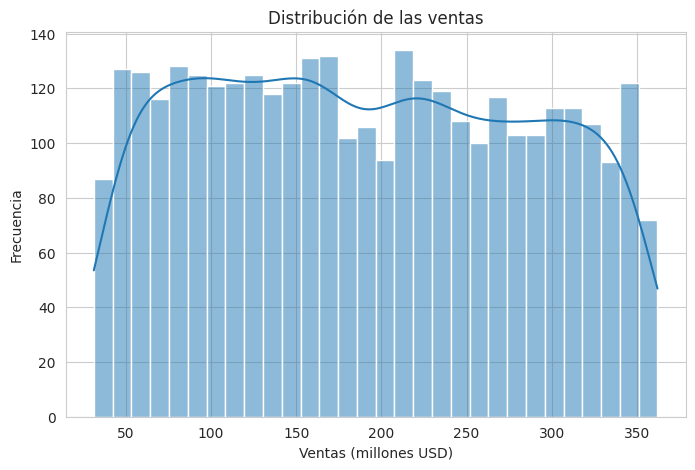

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Sales'], bins=30, kde=True)

plt.title('Distribución de las ventas')
plt.xlabel('Ventas (millones USD)')
plt.ylabel('Frecuencia')

plt.show()

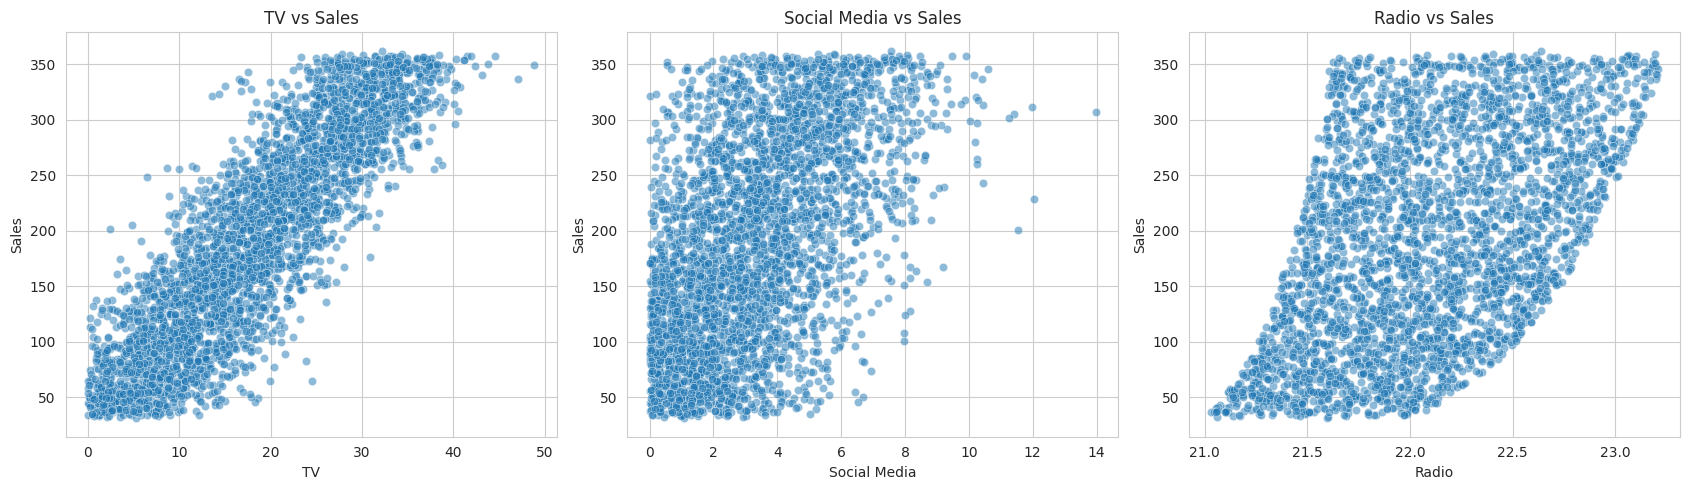

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

variables = ['TV', 'Social Media', 'Radio']

for i, variable in enumerate(variables):

    sns.scatterplot(
        data=df,
        x=variable,
        y='Sales',
        ax=axes[i],
        alpha=0.5
    )

    axes[i].set_title(f'{variable} vs Sales')

plt.tight_layout()
plt.show()

#Interpretación:
 Los gráficos permiten observar que las ventas aumentan a medida que crece la inversión en televisión y radio, aunque cada medio presenta un comportamiento diferente. En televisión se observa una tendencia creciente más clara, mientras que en redes sociales los datos están más dispersos y no muestran una relación tan evidente. Esto permite identificar que las inversiones publicitarias pueden relacionarse de distintas maneras con las ventas y que es importante utilizar modelos capaces de reconocer estos comportamientos.

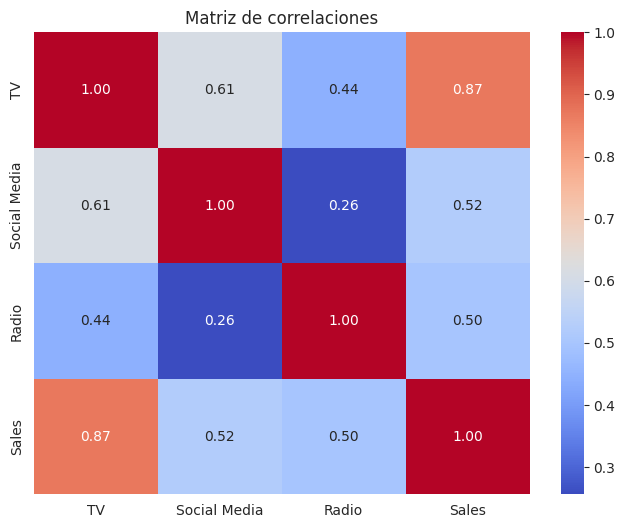

In [ ]:
correlaciones = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlaciones')

plt.show()

#Interpretación:
La inversión en televisión presenta la mayor relación con las ventas, con una correlación de 0.87, seguida de las redes sociales con 0.52 y la radio con 0.50. Esto indica que la relación entre la inversión en televisión y las ventas es más fuerte que la observada en los otros medios publicitarios. Estos resultados permiten identificar diferencias en el comportamiento de las variables y sirven como referencia para la selección de los modelos predictivos.

# 3. Preprocesamiento de los datos

#3.1. Separar las variables predictoras y la variable objetivo

In [ ]:
# Variables predictoras
X = df.drop(columns=['Sales'])

# Variable objetivo
y = df['Sales']

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (3409, 4)
Dimensiones de y: (3409,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de validación:", X_test.shape)

print("\nObservaciones para entrenamiento:", len(y_train))
print("Observaciones para validación:", len(y_test))

Datos de entrenamiento: (2727, 4)
Datos de validación: (682, 4)

Observaciones para entrenamiento: 2727
Observaciones para validación: 682


#Interpretación:
 Separamos los datos en dos grupos: el 80% (2.727 observaciones) para entrenar el modelo y el 20% (682 observaciones) para evaluar sus resultados. Utilizamos `random_state=42` para que la división siempre sea la misma. No usamos `stratify` porque las ventas son valores continuos. Así podremos comprobar qué tan bien predice el modelo con datos que no ha utilizado durante el entrenamiento.

#3.3. Identificar las variables numéricas y categóricas

In [ ]:
# Identificar variables numéricas
numerical_features = X_train.select_dtypes(
    include=np.number
).columns

# Identificar variables categóricas
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns

print("Variables numéricas:")
print(list(numerical_features))

print("\nVariables categóricas:")
print(list(categorical_features))

Variables numéricas:
['TV', 'Social Media', 'Radio']

Variables categóricas:
['Influencer']


#3.4. Codificar la variable categórica

In [ ]:
# Transformación de variables categóricas
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    drop='first'
)

# Crear el preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            categorical_transformer,
            categorical_features
        ),
        (
            'num',
            'passthrough',
            numerical_features
        )
    ]
)

print("Preprocesador creado correctamente")

Preprocesador creado correctamente


# Interpretación:
El preprocesador convertirá la variable `Influencer` en valores numéricos y mantendrá `TV`, `Social Media` y `Radio` sin cambios. Este proceso se realizará dentro de cada modelo para que aprenda únicamente con los datos de entrenamiento y evitar que utilice información de los datos de validación antes de tiempo.

# 4. Entrenamiento y optimización de los modelos

# 4.1. Crear los pipelines de los modelos

In [ ]:
# Modelo 1: Random Forest Regressor

modelo_rf = Pipeline([
    ('preprocessor', preprocessor),

    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])


# Modelo 2: Gradient Boosting Regressor

modelo_gb = Pipeline([
    ('preprocessor', preprocessor),

    ('model', GradientBoostingRegressor(
        random_state=42
    ))
])

print("Los dos modelos fueron creados correctamente")

Los dos modelos fueron creados correctamente


#Interpretación:
Tenemos dos modelos preparados: Random Forest, que combina los resultados de varios árboles, y Gradient Boosting, que construye árboles uno tras otro para corregir los errores anteriores.

#4.2. Configurar los hiperparámetros de Random Forest

In [ ]:
param_grid_rf = {

    'model__n_estimators': [100, 200],

    'model__max_depth': [None, 12],

    'model__min_samples_leaf': [1, 3]

}

# Interpretación:
Antes de optimizar los modelos, debemos definir qué parámetros vamos a probar y qué función cumple cada uno. En total, evaluaremos ocho combinaciones, variando la cantidad de árboles, su profundidad y el número mínimo de observaciones por hoja. El objetivo es encontrar la configuración que tenga el menor error en sus predicciones y evitar que el modelo se ajuste demasiado a los datos de entrenamiento.

#4.3. Configurar los hiperparámetros de Gradient Boosting

In [ ]:
param_grid_gb = {

    'model__n_estimators': [100, 200],

    'model__learning_rate': [0.05, 0.1],

    'model__max_depth': [2, 3]

}

#Interpretación:
En este modelo probaremos ocho combinaciones, modificando la cantidad de árboles, la velocidad con la que se corrigen los errores y la profundidad de cada árbol. Un `learning_rate` más bajo hace que los cambios sean más pequeños, lo que puede ayudar a evitar que el modelo se ajuste demasiado a los datos. El objetivo es encontrar el equilibrio que permita obtener mejores predicciones.

#4.4. Configurar la validación cruzada

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validación cruzada configurada")
print("Número de particiones:", cv.get_n_splits())

Validación cruzada configurada
Número de particiones: 5


#4.5. Entrenar y optimizar Random Forest

In [ ]:
scoring='neg_root_mean_squared_error'

El resultado será negativo porque Scikit-learn trabaja con una convención en la que los valores mayores son mejores. Por eso, al obtener el resultado final, multiplicaremos el valor por -1.

In [ ]:
grid_rf = GridSearchCV(

    estimator=modelo_rf,

    param_grid=param_grid_rf,

    scoring='neg_root_mean_squared_error',

    cv=cv,

    n_jobs=1,

    verbose=1

)

# Entrenar y optimizar
grid_rf.fit(X_train, y_train)

# Mejor configuración
print("Mejores hiperparámetros de Random Forest:")

print(grid_rf.best_params_)

# RMSE de validación cruzada
rmse_cv_rf = -grid_rf.best_score_

print("\nRMSE de validación cruzada:")

print(rmse_cv_rf)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores hiperparámetros de Random Forest:
{'model__max_depth': 12, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}

RMSE de validación cruzada:
44.378446830531665


# Interpretación:
La mejor configuración encontrada utiliza 200 árboles, una profundidad máxima de 12 y un mínimo de tres observaciones por hoja. Con esta combinación se obtuvo un RMSE de 44.38, siendo la que presentó el menor error promedio entre las diferentes opciones evaluadas.

#4.6. Entrenar y optimizar Gradient Boosting

In [ ]:
grid_gb = GridSearchCV(

    estimator=modelo_gb,

    param_grid=param_grid_gb,

    scoring='neg_root_mean_squared_error',

    cv=cv,

    n_jobs=1,

    verbose=1

)

# Entrenar y optimizar
grid_gb.fit(X_train, y_train)

# Mejor configuración
print("Mejores hiperparámetros de Gradient Boosting:")

print(grid_gb.best_params_)

# RMSE de validación cruzada
rmse_cv_gb = -grid_gb.best_score_

print("\nRMSE de validación cruzada:")

print(rmse_cv_gb)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mejores hiperparámetros de Gradient Boosting:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}

RMSE de validación cruzada:
42.60199269262869


#Interpretación:
La mejor configuración utiliza 100 árboles, una tasa de aprendizaje de 0.05 y una profundidad máxima de tres. Con estos valores se obtuvo un RMSE de 42.60, menor que el de Random Forest. Esto indica que Gradient Boosting tuvo mejores resultados en las pruebas iniciales, aunque todavía debemos comprobar su rendimiento con los datos de validación.

#5. Comparación y selección del mejor modelo

#5.1. Obtener las predicciones

In [ ]:
# Obtener los mejores modelos
mejor_rf = grid_rf.best_estimator_

mejor_gb = grid_gb.best_estimator_

# Predicciones sobre entrenamiento
pred_rf_train = mejor_rf.predict(X_train)

pred_gb_train = mejor_gb.predict(X_train)

# Predicciones sobre validación
pred_rf_test = mejor_rf.predict(X_test)

pred_gb_test = mejor_gb.predict(X_test)

print("Predicciones realizadas correctamente")

Predicciones realizadas correctamente


#5.2. Calcular el RMSE de cada modelo

In [ ]:
# Random Forest

rmse_rf_train = np.sqrt(
    mean_squared_error(y_train, pred_rf_train)
)

rmse_rf_test = np.sqrt(
    mean_squared_error(y_test, pred_rf_test)
)


# Gradient Boosting

rmse_gb_train = np.sqrt(
    mean_squared_error(y_train, pred_gb_train)
)

rmse_gb_test = np.sqrt(
    mean_squared_error(y_test, pred_gb_test)
)


print("RESULTADOS RANDOM FOREST")

print("RMSE entrenamiento:", rmse_rf_train)

print("RMSE validación:", rmse_rf_test)


print("\nRESULTADOS GRADIENT BOOSTING")

print("RMSE entrenamiento:", rmse_gb_train)

print("RMSE validación:", rmse_gb_test)

RESULTADOS RANDOM FOREST
RMSE entrenamiento: 29.39396583606978
RMSE validación: 43.531195789906185

RESULTADOS GRADIENT BOOSTING
RMSE entrenamiento: 40.219832365794254
RMSE validación: 42.351127261217634


#Interpretación:
Random Forest presenta un menor error durante el entrenamiento, pero este aumenta al trabajar con datos nuevos, lo que indica que tiene una mayor diferencia entre su desempeño durante el aprendizaje y la validación. Por su parte, Gradient Boosting muestra errores más parecidos en ambos casos, lo que refleja un comportamiento más estable. Además, obtuvo el menor RMSE de validación, por lo que presenta mejores resultados en nuestra comparación.

#5.3. Calcular métricas complementarias

In [ ]:
# MAE
mae_rf = mean_absolute_error(y_test, pred_rf_test)

mae_gb = mean_absolute_error(y_test, pred_gb_test)


# R2
r2_rf = r2_score(y_test, pred_rf_test)

r2_gb = r2_score(y_test, pred_gb_test)


print("RANDOM FOREST")

print("MAE:", mae_rf)

print("R2:", r2_rf)


print("\nGRADIENT BOOSTING")

print("MAE:", mae_gb)

print("R2:", r2_gb)

RANDOM FOREST
MAE: 33.88795064431428
R2: 0.7821648211763517

GRADIENT BOOSTING
MAE: 33.04135569726697
R2: 0.7938151406191891


#Interpretación:
Gradient Boosting presenta un error promedio ligeramente menor que Random Forest, con un MAE de 33.04 frente a 33.89. Además, obtiene un R² de 0.794 frente a 0.782, lo que significa que logra explicar una mayor parte de las variaciones observadas en las ventas. Por lo tanto, también presenta mejores resultados en estas métricas complementarias.

# 5.4. Construir la tabla comparativa final

In [ ]:
resultados = pd.DataFrame({

    'Modelo': [
        'Random Forest',
        'Gradient Boosting'
    ],

    'RMSE_CV': [
        -grid_rf.best_score_,
        -grid_gb.best_score_
    ],

    'RMSE_Entrenamiento': [
        rmse_rf_train,
        rmse_gb_train
    ],

    'RMSE_Validacion': [
        rmse_rf_test,
        rmse_gb_test
    ],

    'MAE': [
        mae_rf,
        mae_gb
    ],

    'R2': [
        r2_rf,
        r2_gb
    ]

})

# Ordenar según el RMSE de validación
resultados = resultados.sort_values(
    by='RMSE_Validacion',
    ascending=True
)

resultados

,Modelo,RMSE_CV,RMSE_Entrenamiento,RMSE_Validacion,MAE,R2
1,Gradient Boosting,42.601993,40.219832,42.351127,33.041356,0.793815
0,Random Forest,44.378447,29.393966,43.531196,33.887951,0.782165


#5.5. Seleccionar el mejor modelo automáticamente

In [ ]:
# Identificar el modelo con menor RMSE
mejor_modelo_nombre = resultados.iloc[0]['Modelo']

menor_rmse = resultados.iloc[0]['RMSE_Validacion']

print("MODELO GANADOR")

print("Modelo seleccionado:", mejor_modelo_nombre)

print("RMSE obtenido:", menor_rmse)

MODELO GANADOR
Modelo seleccionado: Gradient Boosting
RMSE obtenido: 42.351127261217634


#6. Entrenamiento final con toda la base disponible

In [ ]:
# Seleccionar el mejor modelo
modelo_final = grid_gb.best_estimator_

# Entrenar con toda la base disponible
modelo_final.fit(X, y)

print("Modelo final entrenado correctamente")

Modelo final entrenado correctamente


In [ ]:
import joblib

joblib.dump(
    modelo_final,
    'modelo_gradient_boosting_ventas.pkl'
)

print("Modelo guardado correctamente")

Modelo guardado correctamente


# Interpretación
Al finalizar este proceso, obtenemos el modelo Gradient Boosting entrenado con todos los datos disponibles, listo para realizar predicciones sobre nuevos registros. Es importante tener en cuenta que el RMSE reportado sigue siendo el calculado con los datos de validación, ya que estos se utilizaron para comparar los modelos antes de entrenar el definitivo con toda la información.

#7. Conclusión y recomendación final

#7.1. ¿Por qué ganó Gradient Boosting?

Gradient Boosting fue el modelo ganador por tres razones: obtuvo un menor RMSE de validación (42.3511) frente a Random Forest (43.5312), presentó resultados más estables entre el entrenamiento y la validación y consiguió mejores resultados en las métricas MAE y R². En general, sus predicciones tuvieron un menor error, por lo que presentó el mejor desempeño entre los dos modelos evaluados.

#7.2. Conclusión para el trabajo

Después de explorar los datos, preparar la información y entrenar los modelos Random Forest y Gradient Boosting, encontramos que Gradient Boosting tuvo el mejor desempeño. Obtuvo un RMSE de 42.3511, un MAE de 33.0414 y un R² de 0.7938, superando los resultados de Random Forest, que obtuvo un RMSE de 43.5312, un MAE de 33.8880 y un R² de 0.7822.

Además, Gradient Boosting presentó una menor diferencia entre el error de entrenamiento y el de validación, mostrando un comportamiento más estable. Por esta razón, seleccionamos Gradient Boosting como el modelo ganador, ya que logró realizar predicciones con menor error sobre los datos evaluados.